# Lab01 - sprint 1
**Датасет:** CalCOFI (океанографические наблюдения у берегов Калифорнии)
**Моя случайная величина:** температура воды `T_degC`,°C

**Содержание:** Description · Proof of randomness · EDA & Distribution · Normalization · Independence & Estimations · Sampling · Distribution · Hypothesis testing · Выводы · Lab resume

## Random Variable 01 — температура воды (`T_degC`)

### Description (природа события)

Датасет CalCOFI — это результаты многолетних океанографических экспедиций у берегов Калифорнии. Корабль приходит на станцию, опускает в воду батометры (бутылки для отбора воды) на разные глубины и измеряет параметры воды: температуру, солёность, кислород и т. д.

Одна строка таблицы = одна «бутылка» = один отбор воды на конкретной глубине, на конкретной станции, в конкретное время.

Температура воды `T_degC` измеряется в градусах Цельсия. Она зависит от очень многих факторов: сезона, времени суток, течений, погоды, глубины, района, вихрей, явлений типа Эль-Ниньо, плюс есть ошибка самого прибора. Все эти факторы учесть и записать одной формулой невозможно, поэтому *заранее* точное значение температуры мы не знаем, мы можем только измерить его. Это и есть случайная величина.

**Тип величины:** непрерывная (температура может принимать любое значение на отрезке).

### Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
import kagglehub
path = kagglehub.dataset_download("sohier/calcofi")
DATA_PATH = path + "/bottle.csv"

df = pd.read_csv(DATA_PATH, usecols=["Sta_ID", "Depthm", "T_degC", "Salnty"],
                 encoding="latin-1", low_memory=False)
print("Размер таблицы:", df.shape)
df.head()

100%|██████████| 50.4M/50.4M [00:00<00:00, 54.3MB/s]

Extracting files...


Размер таблицы: (864863, 4)


,Sta_ID,Depthm,T_degC,Salnty
0,054.0 056.0,0,10.50,33.440
1,054.0 056.0,8,10.46,33.440
2,054.0 056.0,10,10.46,33.437
3,054.0 056.0,19,10.45,33.420
4,054.0 056.0,20,10.45,33.421


In [3]:
print("Пропуски в каждой колонке:")
print(df.isna().sum())

temp = df["T_degC"].dropna().reset_index(drop=True)
N = len(temp)
print(f"\nN (размер генеральной совокупности) = {N}")

Пропуски в каждой колонке:
Sta_ID        0
Depthm        0
T_degC    10963
Salnty    47354
dtype: int64

N (размер генеральной совокупности) = 853900


В столбце `T_degC` было 10 963 пропуска из 864 863 строк (около 1,3 %). Скорее всего, в этих пробах температуру просто не записали. Заполнять пропуски средним или другим числом я не стал: это исказило бы распределение, а данных и так достаточно. Остался 853 900 значений, они и считаются **генеральной совокупностью** (N = 853 900). Выбросы, не связанные с пропусками, на этом шаге не трогаем.

### Proof of randomness (почему это случайная величина)

Идея доказательства: если бы температуру можно было посчитать по формуле, то при одинаковых «входных параметрах» мы получали бы одинаковый результат. Главный и самый очевидный параметр, от которого зависит температура, — глубина. Возьмём срез на одной глубине (поверхность, `Depthm = 0`) и посмотрим, будет ли температура одинаковой.

Измерений на глубине 0 м: 32344
Количество разных значений температуры: 2873
Минимум: 8.36 °C, максимум: 31.14 °C
Среднее: 16.47 °C, стд. отклонение: 2.94 °C


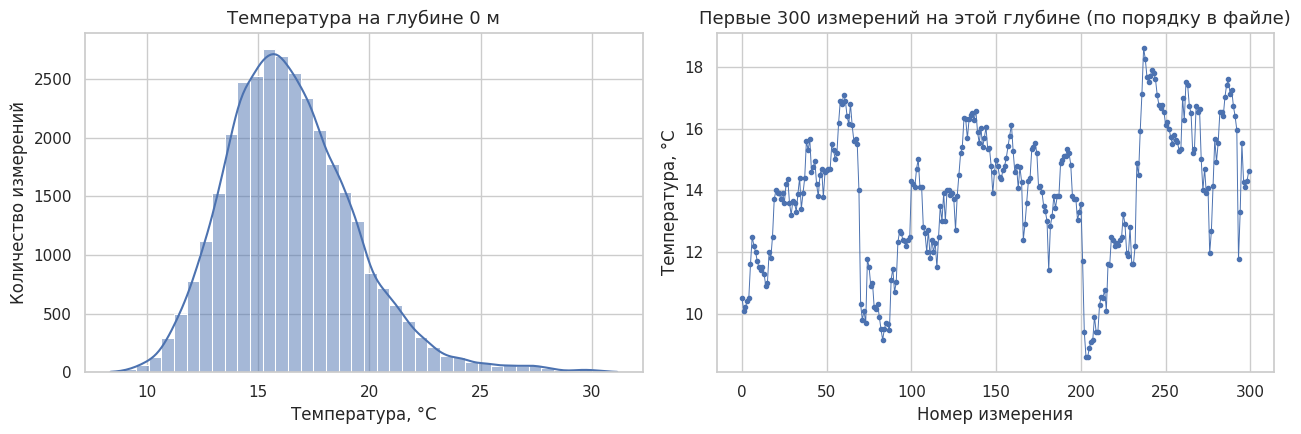

In [4]:
DEPTH = 0
surface = df.loc[df["Depthm"] == DEPTH, "T_degC"].dropna()

print(f"Измерений на глубине {DEPTH} м: {len(surface)}")
print(f"Количество разных значений температуры: {surface.nunique()}")
print(f"Минимум: {surface.min():.2f} °C, максимум: {surface.max():.2f} °C")
print(f"Среднее: {surface.mean():.2f} °C, стд. отклонение: {surface.std():.2f} °C")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(surface, bins=40, kde=True, ax=ax[0])
ax[0].set_title(f"Температура на глубине {DEPTH} м")
ax[0].set_xlabel("Температура, °C"); ax[0].set_ylabel("Количество измерений")

ax[1].plot(surface.values[:300], marker=".", lw=0.7)
ax[1].set_title("Первые 300 измерений на этой глубине (по порядку в файле)")
ax[1].set_xlabel("Номер измерения"); ax[1].set_ylabel("Температура, °C")
plt.tight_layout(); plt.show()

Глубина одна и та же, а температура разная — разброс заметный. Значит, глубина не определяет температуру однозначно.

Проверим то же самое ещё одним способом: попробуем *построить формулу* $T = f(\text{depth})$ и посмотрим, какую долю разброса она объясняет. Для этого приблизим зависимость полиномом 5-й степени от $\ln(1+\text{depth})$ и посчитаем коэффициент детерминации $R^2$:

$$R^2 = 1 - \frac{\sum_i (T_i - \hat T_i)^2}{\sum_i (T_i - \bar T)^2}$$

Если бы температура считалась по формуле, $R^2$ было бы равно 1.

R^2 модели 'температура = f(глубина)': 0.782
Стд. отклонение остатков: 1.98 °C


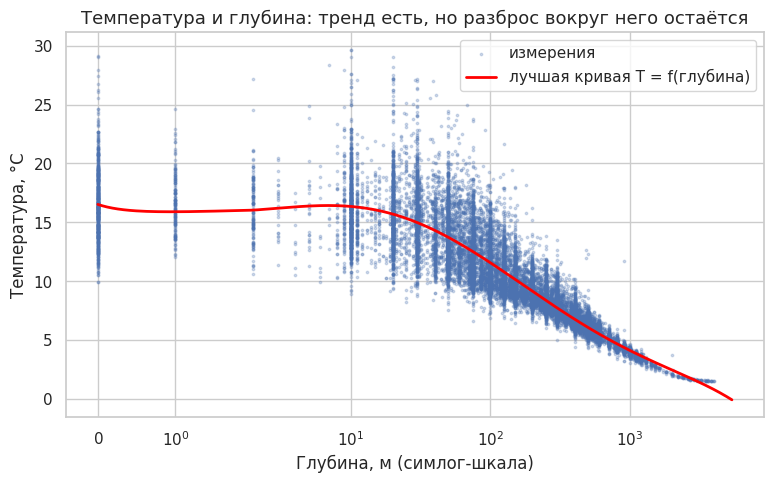

In [5]:
sub = df[["Depthm", "T_degC"]].dropna()
x = np.log1p(sub["Depthm"].values)
y = sub["T_degC"].values

coef = np.polyfit(x, y, deg=5)
y_hat = np.polyval(coef, x)
r2 = 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)
resid_std = np.std(y - y_hat)

print(f"R^2 модели 'температура = f(глубина)': {r2:.3f}")
print(f"Стд. отклонение остатков: {resid_std:.2f} °C")

idx = rng.choice(len(sub), size=min(20000, len(sub)), replace=False)
plt.scatter(sub["Depthm"].values[idx], y[idx], s=3, alpha=0.25, label="измерения")
xs = np.linspace(x.min(), x.max(), 300)
plt.plot(np.expm1(xs), np.polyval(coef, xs), color="red", lw=2, label="лучшая кривая T = f(глубина)")
plt.xscale("symlog")
plt.xlabel("Глубина, м (симлог-шкала)"); plt.ylabel("Температура, °C")
plt.title("Температура и глубина: тренд есть, но разброс вокруг него остаётся")
plt.legend(); plt.show()

**Вывод по пункту.** На поверхности (0 м) мы получили 32 344 измерения, и среди них 2 873 разных значения температуры. Минимум 8,36 °C, максимум 31,14 °C, среднее 16,47 °C, стандартное отклонение 2,94 °C. Если бы температура считалась по формуле от глубины, на одной глубине все значения были бы одинаковыми, а std равнялся бы нулю. Здесь это не так.

Модель «температура = полином от ln(1 + глубина)» объясняет $R^2 = 0{,}782$ изменчивости, то есть около 78 %. Остальные 22 % остаются, стандартное отклонение остатков 1,98 °C. Эти 22 % приходятся на сезон, место станции, год (например, Эль-Ниньо), течения, погоду и погрешность прибора. Заранее всё это учесть нельзя, поэтому температура — **случайная величина**: даже зная глубину, мы не можем точно предсказать значение до измерения.

### EDA & Distribution

In [6]:
desc = temp.describe()
extra = pd.Series({
    "variance": temp.var(ddof=1),
    "median": temp.median(),
    "mode (округл. до 0.1)": temp.round(1).mode().iloc[0],
    "skewness (асимметрия)": stats.skew(temp),
    "kurtosis (эксцесс)": stats.kurtosis(temp),
    "range (размах)": temp.max() - temp.min(),
})
pd.concat([desc, extra]).to_frame("T_degC").round(3)

,T_degC
count,853900.000
mean,10.800
std,4.244
min,1.440
25%,7.680
50%,10.060
75%,13.880
max,31.140
variance,18.010
median,10.060


Что смотрим:
- **среднее и медиана** — если сильно различаются, распределение несимметричное;
- **дисперсия / стд. отклонение** — разброс;
- **асимметрия** $\gamma_1 = E\left[\left(\frac{X-\mu}{\sigma}\right)^3\right]$: 0 для симметричного распределения, >0 — правый хвост длиннее;
- **эксцесс** $\gamma_2 = E\left[\left(\frac{X-\mu}{\sigma}\right)^4\right] - 3$: 0 у нормального.

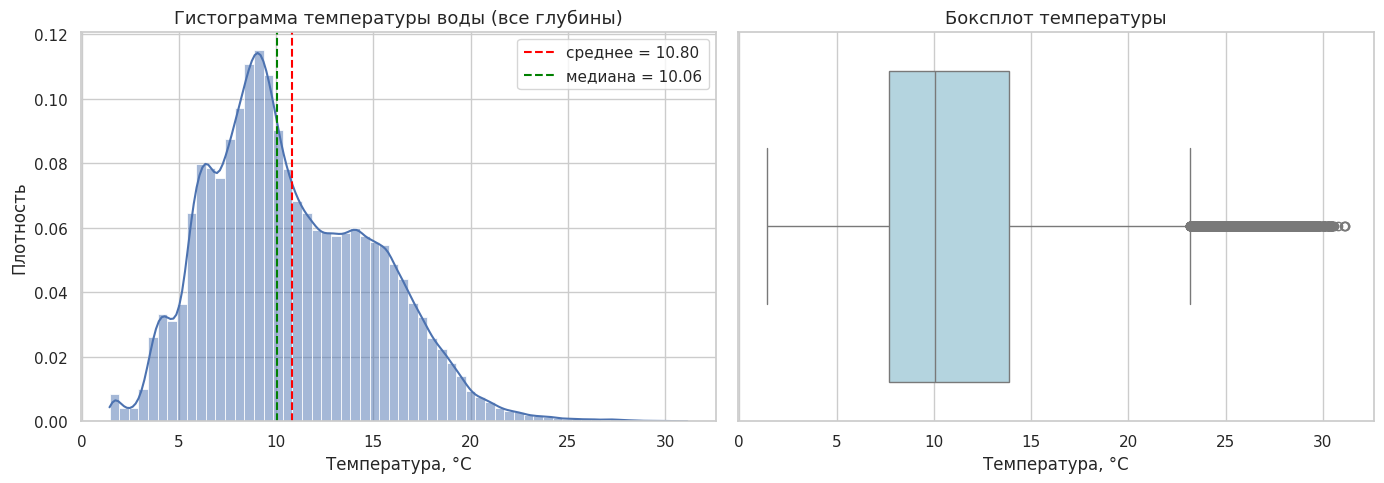

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(temp, bins=60, stat="density", kde=True, ax=ax[0])
ax[0].axvline(temp.mean(), color="red", ls="--", label=f"среднее = {temp.mean():.2f}")
ax[0].axvline(temp.median(), color="green", ls="--", label=f"медиана = {temp.median():.2f}")
ax[0].set_title("Гистограмма температуры воды (все глубины)")
ax[0].set_xlabel("Температура, °C"); ax[0].set_ylabel("Плотность")
ax[0].legend()

sns.boxplot(x=temp, ax=ax[1], color="lightblue")
ax[1].set_title("Боксплот температуры")
ax[1].set_xlabel("Температура, °C")
plt.tight_layout(); plt.show()

Выбросы ищем по правилу 1,5×IQR. Если $Q_1$ и $Q_3$ — первый и третий квартили, $IQR = Q_3 - Q_1$, то выбросами считаем значения вне интервала

$$[\,Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR\,].$$

In [8]:
q1, q3 = temp.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = temp[(temp < low) | (temp > high)]

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Границы без выбросов: [{low:.2f}, {high:.2f}]")
print(f"Выбросов: {len(outliers)} ({100 * len(outliers) / N:.3f}% данных)")
if len(outliers):
    print(f"Выбросы лежат в диапазоне {outliers.min():.2f} ... {outliers.max():.2f} °C")

Q1 = 7.68, Q3 = 13.88, IQR = 6.20
Границы без выбросов: [-1.62, 23.18]
Выбросов: 3738 (0.438% данных)
Выбросы лежат в диапазоне 23.19 ... 31.14 °C


**Вывод по EDA.**

Среднее 10,80 °C, медиана 10,06 °C, стандартное отклонение 4,24 °C (дисперсия 18,01 °C²). Минимум 1,44 °C, максимум 31,14 °C, размах 29,70 °C. Средние 50 % измерений лежат между 7,68 и 13,88 °C (IQR = 6,20 °C). Среднее больше медианы на 0,74 °C, асимметрия +0,49, то есть правый хвост длиннее. Эксцесс −0,11, почти как у нормального распределения: тяжёлых хвостов нет.

По правилу 1,5×IQR границы равны −1,62 и 23,18 °C. Выбросов сверху 3 738 штук (0,44 % данных), они лежат в диапазоне 23,19–31,14 °C. Снизу выбросов нет, потому что нижняя граница отрицательная, а минимум 1,44 °C.

На гистограмме видно не один колокол, а главный пик около 9 °C с небольшими «горбами» около 4 и 6,5 °C и «плечом» около 14–15 °C, потом длинный правый хвост. Так получается потому, что в датасете смешаны разные глубины, сезоны и районы. Боксплот этого не показывает: по нему видно только квартили и выбросы. Поэтому форму распределения я оцениваю по гистограмме, а боксплот использую для разброса и выбросов.

### Normalization

Два способа нормализации:

**Min-max** — приводит значения к отрезку $[0, 1]$:
$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

**Z-преобразование (стандартизация)** — среднее 0, стд. отклонение 1:
$$z = \frac{x - \bar x}{s}$$

Z-преобразование нужно, чтобы сравнивать величины в разных единицах и приводить нормальное распределение к стандартному $N(0,1)$. Форма распределения при обоих преобразованиях не меняется — меняются только масштаб и сдвиг.

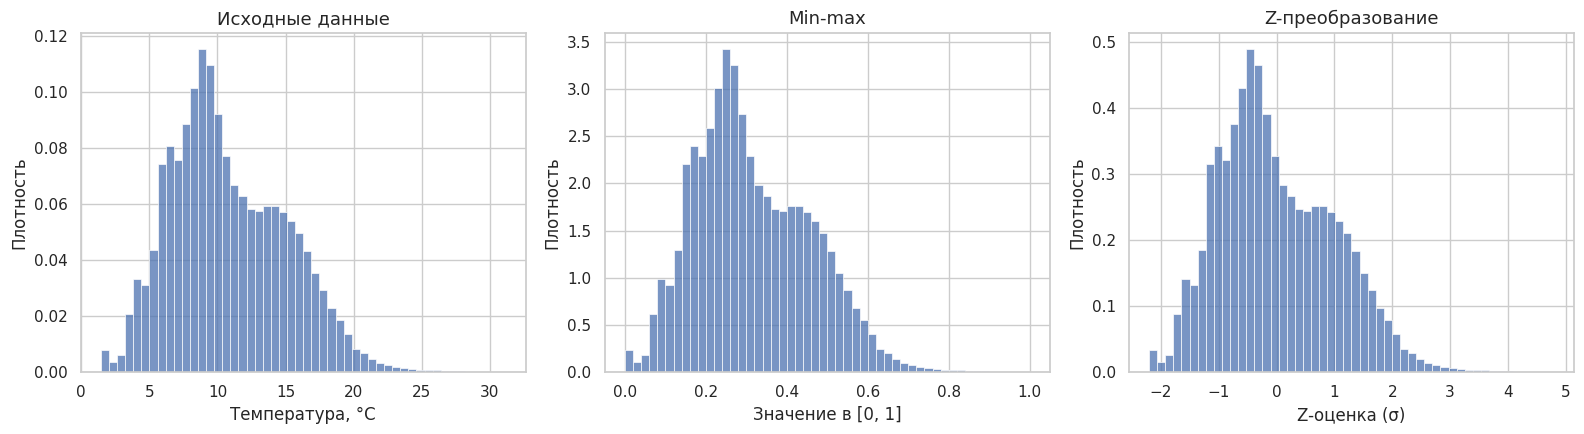

,исходные,min-max,z-score
min,1.4400,0.0000,-2.2055
max,31.1400,1.0000,4.7929
mean,10.7997,0.3151,0.0000
std,4.2438,0.1429,1.0000
skew,0.4886,0.4886,0.4886


In [9]:
temp_minmax = (temp - temp.min()) / (temp.max() - temp.min())
temp_z = (temp - temp.mean()) / temp.std(ddof=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, data, title, xl in zip(
        ax, [temp, temp_minmax, temp_z],
        ["Исходные данные", "Min-max", "Z-преобразование"],
        ["Температура, °C", "Значение в [0, 1]", "Z-оценка (σ)"]):
    sns.histplot(data, bins=50, stat="density", ax=a)
    a.set_title(title); a.set_xlabel(xl); a.set_ylabel("Плотность")
plt.tight_layout(); plt.show()

check = pd.DataFrame({
    "исходные": [temp.min(), temp.max(), temp.mean(), temp.std(), stats.skew(temp)],
    "min-max":  [temp_minmax.min(), temp_minmax.max(), temp_minmax.mean(), temp_minmax.std(), stats.skew(temp_minmax)],
    "z-score":  [temp_z.min(), temp_z.max(), temp_z.mean(), temp_z.std(), stats.skew(temp_z)],
}, index=["min", "max", "mean", "std", "skew"]).round(4)
check

**Вывод по нормализации.** После min-max минимум стал 0, максимум 1, среднее 0,315, std 0,143. После Z-преобразования среднее 0 и std 1, значения лежат от −2,21 до +4,79. Асимметрия во всех трёх вариантах одинаковая (0,489), значит, форма распределения не поменялась, изменились только сдвиг и масштаб.

Z-преобразование здесь удобнее: сразу видно, на сколько сигм значение отличается от среднего. Например, максимум 31,14 °C лежит почти на 4,8 сигмы выше среднего, и это согласуется с выбросами из EDA. К стандартному нормальному распределению данные приводить нельзя, так как они не нормальные (см. гипотезы ниже).

### Independence & Estimations

Независимость проверять не нужно: в этой работе я анализирую одну величину, а не две величины одной природы.

#### Состоятельность оценок

Оценка $\hat\theta_n$ называется **состоятельной**, если она сходится по вероятности к истинному значению параметра при росте объёма выборки:
$$\forall \varepsilon>0:\quad P\big(|\hat\theta_n - \theta| > \varepsilon\big)\to 0,\quad n\to\infty.$$

Проверяем эмпирически для среднего $\bar x$ и выборочной дисперсии $s^2$ (с поправкой Бесселя, $n-1$). За «истинные» значения принимаем $\mu$ и $\sigma^2$ по всей генеральной совокупности.

Для каждого размера выборки $n$ делаем 30 повторных выборок, чтобы увидеть не одну случайную реализацию, а коридор разброса.

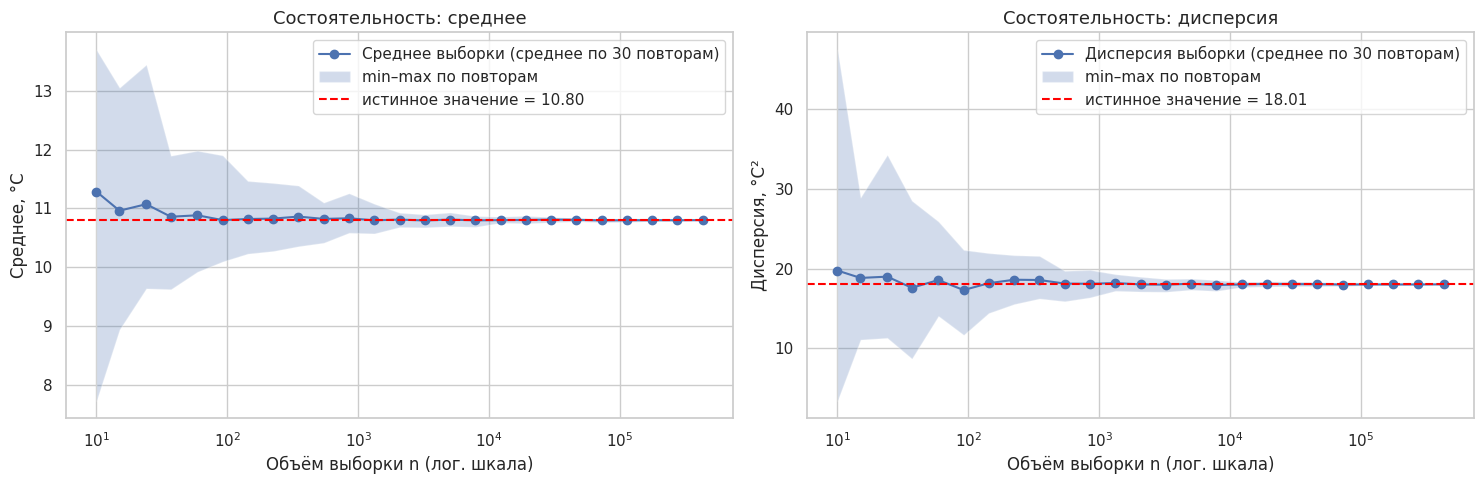

In [10]:
arr = temp.values
mu_true = arr.mean()
var_true = arr.var(ddof=1)

sizes = np.unique(np.logspace(1, np.log10(N // 2), 25).astype(int))
REPS = 30

mean_res = np.zeros((len(sizes), REPS))
var_res = np.zeros((len(sizes), REPS))
for i, n in enumerate(sizes):
    for r in range(REPS):
        s = rng.choice(arr, size=n, replace=False)
        mean_res[i, r] = s.mean()
        var_res[i, r] = s.var(ddof=1)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, res, true, name in zip(ax, [mean_res, var_res], [mu_true, var_true], ["Среднее", "Дисперсия"]):
    a.plot(sizes, res.mean(axis=1), marker="o", label=f"{name} выборки (среднее по {REPS} повторам)")
    a.fill_between(sizes, res.min(axis=1), res.max(axis=1), alpha=0.25, label="min–max по повторам")
    a.axhline(true, color="red", ls="--", label=f"истинное значение = {true:.2f}")
    a.set_xscale("log"); a.set_xlabel("Объём выборки n (лог. шкала)")
    a.set_title(f"Состоятельность: {name.lower()}")
    a.legend()
ax[0].set_ylabel("Среднее, °C"); ax[1].set_ylabel("Дисперсия, °C²")
plt.tight_layout(); plt.show()

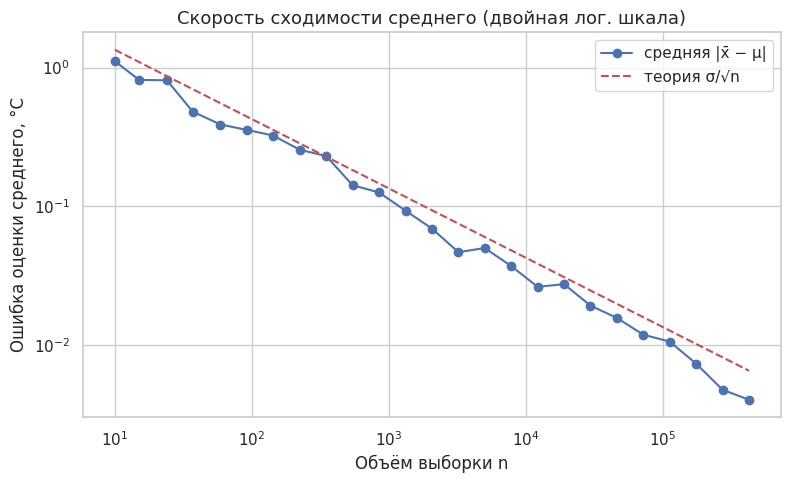

In [11]:
err_mean = np.abs(mean_res - mu_true).mean(axis=1)
plt.loglog(sizes, err_mean, marker="o", label="средняя |x̄ − μ|")
plt.loglog(sizes, np.sqrt(var_true) / np.sqrt(sizes), "r--", label="теория σ/√n")
plt.xlabel("Объём выборки n"); plt.ylabel("Ошибка оценки среднего, °C")
plt.title("Скорость сходимости среднего (двойная лог. шкала)")
plt.legend(); plt.show()

**Вывод по состоятельности.** При малых выборках (n около 10) среднее сильно «скачет»: на графике коридор разброса по 30 повторам для среднего идёт примерно от 7,8 до 13,7 °C при истинном значении 10,80 °C, а у дисперсии от 3 до 47 °C² при истинной 18,01 °C². С ростом n коридор быстро сужается, примерно с n около 1000 среднее и дисперсия уже почти совпадают с красной линией, а при n в десятки тысяч практически не отличаются.

На лог-лог графике ошибка среднего идёт параллельно теоретической линии $\sigma/\sqrt{n}$, как и должно быть по ЦПТ. Значит, выборочные среднее и дисперсия — **состоятельные оценки**. Чтобы оценить параметры всех 853 900 измерений, достаточно выборки в несколько тысяч значений.

### Sampling: с возвращением и без возвращения

**С возвращением**: каждый элемент после выбора кладётся обратно, выбор независимый, один элемент может попасть в выборку несколько раз. Дисперсия выборочного среднего: $\mathrm{Var}(\bar x)=\dfrac{\sigma^2}{n}$.

**Без возвращения**: элемент выбирается один раз, выбор слегка зависимый. Дисперсия среднего меньше за счёт поправки на конечную совокупность (FPC):
$$\mathrm{Var}(\bar x)=\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}.$$

Когда $n \ll N$, поправка почти равна 1 и разницы практически нет. Её видно, когда $n$ сравнимо с $N$.

In [12]:
n = 5000

samp_with = rng.choice(arr, size=n, replace=True)
samp_without = rng.choice(arr, size=n, replace=False)

def stat_row(x, ddof=1):
    return {"n": len(x), "mean": np.mean(x), "median": np.median(x), "var": np.var(x, ddof=ddof),
            "std": np.std(x, ddof=ddof), "min": np.min(x), "max": np.max(x), "skew": stats.skew(x)}

table = pd.DataFrame({
    "генеральная (все данные)": stat_row(arr),
    "с возвращением": stat_row(samp_with),
    "без возвращения": stat_row(samp_without),
}).T.round(3)
table

,n,mean,median,var,std,min,max,skew
генеральная (все данные),853900.0,10.800,10.06,18.010,4.244,1.44,31.14,0.489
с возвращением,5000.0,10.929,10.16,18.063,4.250,1.49,30.06,0.441
без возвращения,5000.0,10.798,10.08,17.852,4.225,1.50,28.06,0.447


In [13]:
rel = table.loc[["с возвращением", "без возвращения"], ["mean", "median", "var", "std"]]
rel = (rel - table.loc["генеральная (все данные)", ["mean", "median", "var", "std"]]).abs() \
      / table.loc["генеральная (все данные)", ["mean", "median", "var", "std"]] * 100
print("Относительное отклонение от генеральной совокупности, %:")
rel.round(3)

Относительное отклонение от генеральной совокупности, %:


,mean,median,var,std
с возвращением,1.194,0.994,0.294,0.141
без возвращения,0.019,0.199,0.877,0.448


При n = 5000 из N = 853 900 обе выборки очень похожи на генеральную совокупность: отклонения среднего, медианы, дисперсии и std составляют порядка 1 % и меньше (самое большое — среднее выборки с возвращением, 1,19 %). Эту разницу не нужно считать систематической: стандартная ошибка среднего равна $4{,}24/\sqrt{5000}\approx 0{,}06$ °C, то есть 0,56 %, а отклонение 0,129 °C — около 2 стандартных ошибок, обычное дело для одной случайной выборки. Так как n ≪ N, поправка на конечную совокупность практически равна 1 и разницы между схемами не видно.

Чтобы увидеть разницу, возьмём **маленькую «генеральную совокупность»** из 2000 значений и выборки по n = 1500 (три четверти совокупности). Повторим выбор 3000 раз и сравним разброс выборочных средних с теорией.

Среднее генеральной (малой) совокупности: 10.851


,Var(x̄) по эксперименту,Var(x̄) по теории
с возвращением,0.012003,0.011876
без возвращения,0.003091,0.002971


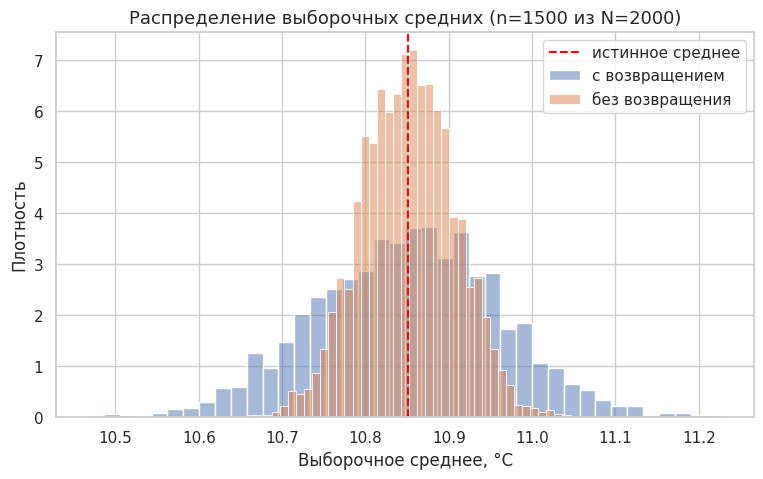

In [14]:
pop = rng.choice(arr, size=2000, replace=False)
N_small, n_small, B = len(pop), 1500, 3000

means_with = np.array([rng.choice(pop, n_small, replace=True).mean() for _ in range(B)])
means_without = np.array([rng.choice(pop, n_small, replace=False).mean() for _ in range(B)])

sigma2 = pop.var(ddof=0)
theory_with = sigma2 / n_small
theory_without = sigma2 / n_small * (N_small - n_small) / (N_small - 1)

res = pd.DataFrame({
    "Var(x̄) по эксперименту": [means_with.var(), means_without.var()],
    "Var(x̄) по теории": [theory_with, theory_without],
}, index=["с возвращением", "без возвращения"])
print(f"Среднее генеральной (малой) совокупности: {pop.mean():.3f}")
display(res.round(6))

sns.histplot(means_with, bins=40, stat="density", color="C0", alpha=0.5, label="с возвращением")
sns.histplot(means_without, bins=40, stat="density", color="C1", alpha=0.5, label="без возвращения")
plt.axvline(pop.mean(), color="red", ls="--", label="истинное среднее")
plt.xlabel("Выборочное среднее, °C"); plt.ylabel("Плотность")
plt.title(f"Распределение выборочных средних (n={n_small} из N={N_small})")
plt.legend(); plt.show()

**Вывод по выборкам.** Центры гистограмм выборочных средних совпадают с истинным средним малой совокупности (10,851 °C): обе схемы дают несмещённую оценку. Но у схемы **без возвращения** дисперсия среднего намного меньше: 0,00309 против 0,01200 с возвращением, то есть в 0,26 раза. Теория даёт $\frac{N-n}{N-1} = \frac{500}{1999} \approx 0{,}25$, так что эксперимент совпадает с формулой (теоретические значения 0,00297 и 0,01188). Это логично: при выборке без возвращения мы берём 75 % совокупности, элементы не повторяются, и среднее выборки уже мало отличается от среднего совокупности. С возвращением часть элементов повторяется и информации меньше. Когда n ≪ N, схемы практически не отличаются.

### Distribution: математическое описание

Подберём теоретическое распределение, которое лучше всего описывает температуру. Рассмотрим нормальное, логнормальное, гамма и Вейбулла (последние три определены только для положительных значений) и сравним их через:
- **критерий Колмогорова–Смирнова** $D = \sup_x |F_n(x) - F(x)|$ (чем меньше, тем лучше);
- **критерий Акаике** $AIC = 2k - 2\ln L$, где $k$ — число параметров, $L$ — максимум правдоподобия (чем меньше, тем лучше).

Параметры подбираются методом максимального правдоподобия (MLE). Для скорости используем случайную подвыборку из 20 000 значений.

In [15]:
fit_data = rng.choice(arr, size=20000, replace=False)
positive = fit_data.min() > 0
print("Все значения > 0:", positive)

candidates = {"norm": stats.norm, "skewnorm": stats.skewnorm}
if positive:
    candidates.update({"lognorm": stats.lognorm, "gamma": stats.gamma, "weibull_min": stats.weibull_min})

rows, fitted = [], {}
for name, dist in candidates.items():
    params = dist.fit(fit_data)
    ll = np.sum(dist.logpdf(fit_data, *params))
    k = len(params)
    ks = stats.kstest(fit_data, dist.cdf, args=params).statistic
    rows.append({"распределение": name, "параметры": np.round(params, 3), "KS D": ks, "AIC": 2 * k - 2 * ll})
    fitted[name] = params

fit_table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
fit_table

Все значения > 0: True


,распределение,параметры,KS D,AIC
0,skewnorm,"[3.107, 5.742, 6.584]",0.032988,113280.377300
1,gamma,"[9.179, -2.168, 1.41]",0.032487,113365.898156
2,weibull_min,"[2.412, 1.168, 10.845]",0.042704,113418.808280
3,lognorm,"[0.224, -8.096, 18.408]",0.034744,113433.320711
4,norm,"[10.778, 4.241]",0.071462,114555.299109


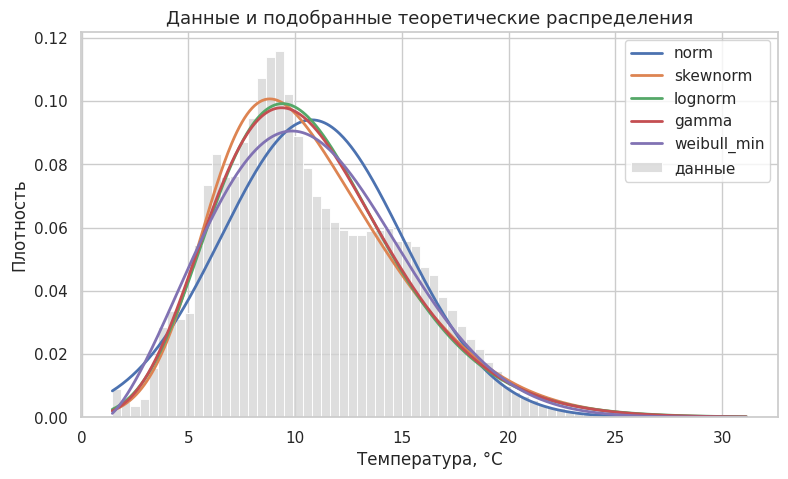

In [16]:
xs = np.linspace(arr.min(), arr.max(), 500)
sns.histplot(arr, bins=70, stat="density", color="lightgray", label="данные")
for name, params in fitted.items():
    plt.plot(xs, candidates[name].pdf(xs, *params), lw=2, label=name)
plt.xlabel("Температура, °C"); plt.ylabel("Плотность")
plt.title("Данные и подобранные теоретические распределения")
plt.legend(); plt.show()

**Нормальное распределение** $N(\mu,\sigma^2)$ — базовый вариант:

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\quad x\in\mathbb R$$

$E[X]=\mu,\; D[X]=\sigma^2$, симметрично относительно $\mu$, асимметрия 0, эксцесс 0. Если $X \sim N(\mu,\sigma^2)$, то $Z=\frac{X-\mu}{\sigma}\sim N(0,1)$. Оценки MLE: $\hat\mu=\bar x$, $\hat\sigma^2=\frac1n\sum(x_i-\bar x)^2$.

**Гамма-распределение** $\Gamma(k,\theta)$ (подходит для положительных величин с правым хвостом):

$$f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\,\theta^{k}},\quad x>0$$

$E[X]=k\theta,\; D[X]=k\theta^2$, асимметрия $2/\sqrt k$.

**Логнормальное** (если $\ln X\sim N(\mu,\sigma^2)$):
$$f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp\left(-\frac{(\ln x-\mu)^2}{2\sigma^2}\right),\quad x>0.$$

**Распределение Вейбулла** $f(x)=\frac{k}{\lambda}\left(\frac{x}{\lambda}\right)^{k-1}e^{-(x/\lambda)^k},\; x>0$ (в `scipy` ещё добавляется параметр сдвига).

**Скошенное нормальное** (skew-normal), оно же лучшее по AIC:
$$f(x)=\frac{2}{\omega}\,\varphi\!\left(\frac{x-\xi}{\omega}\right)\Phi\!\left(\alpha\,\frac{x-\xi}{\omega}\right),$$
где $\varphi$ и $\Phi$ — плотность и функция распределения стандартного нормального, $\xi$ — сдвиг, $\omega$ — масштаб, $\alpha$ — параметр формы. При $\alpha=0$ получается обычное нормальное, при $\alpha>0$ правый хвост длиннее.

**Результаты подбора на подвыборке из 20 000 значений:**

| распределение | KS D | AIC |
|---|---|---|
| skewnorm ($\alpha=3{,}11$, $\xi=5{,}74$, $\omega=6{,}58$) | 0,0330 | 113 280 |
| gamma ($k=9{,}18$, сдвиг $-2{,}17$, $\theta=1{,}41$) | 0,0325 | 113 366 |
| weibull_min | 0,0427 | 113 419 |
| lognorm | 0,0347 | 113 433 |
| norm ($\mu=10{,}78$, $\sigma=4{,}24$) | 0,0715 | 114 555 |

**Вывод.** Нормальное распределение хуже всех: у него и KS D (0,071), и AIC самые большие, потому что оно симметричное, а у данных правый хвост (асимметрия 0,49). Лучшие — скошенное нормальное (минимальный AIC) и гамма (минимальный KS D), разница между ними небольшая. На графике видно, что эти кривые описывают форму «горб + правый хвост», но не повторяют мелкие «горбы» гистограммы около 4, 6,5 и 14–15 °C. Значение KS D порядка 0,03 тоже говорит, что идеального совпадения нет. Причина в смешанной природе данных: в одной величине объединены разные глубины, сезоны и районы, поэтому такое распределение лучше считать смесью нескольких компонент.


### Hypothesis testing

**Гипотеза 1 (о виде распределения).**
$H_0$: температура воды (все глубины) распределена нормально. $H_1$: не нормально. Уровень значимости $\alpha = 0.05$.

Нюанс: при очень больших выборках (сотни тысяч) любой тест «видит» даже мельчайшие отклонения от нормальности и почти всегда отвергает $H_0$. Поэтому тесты делаем на подвыборке 5000 и дополнительно смотрим Q–Q график.

,статистика,p-value,решение при α=0.05
Shapiro-Wilk,0.979666,3.521288e-26,отвергаем H0
D'Agostino-Pearson,173.838655,1.784085e-38,отвергаем H0
Kolmogorov-Smirnov,0.074754,9.567751e-25,отвергаем H0


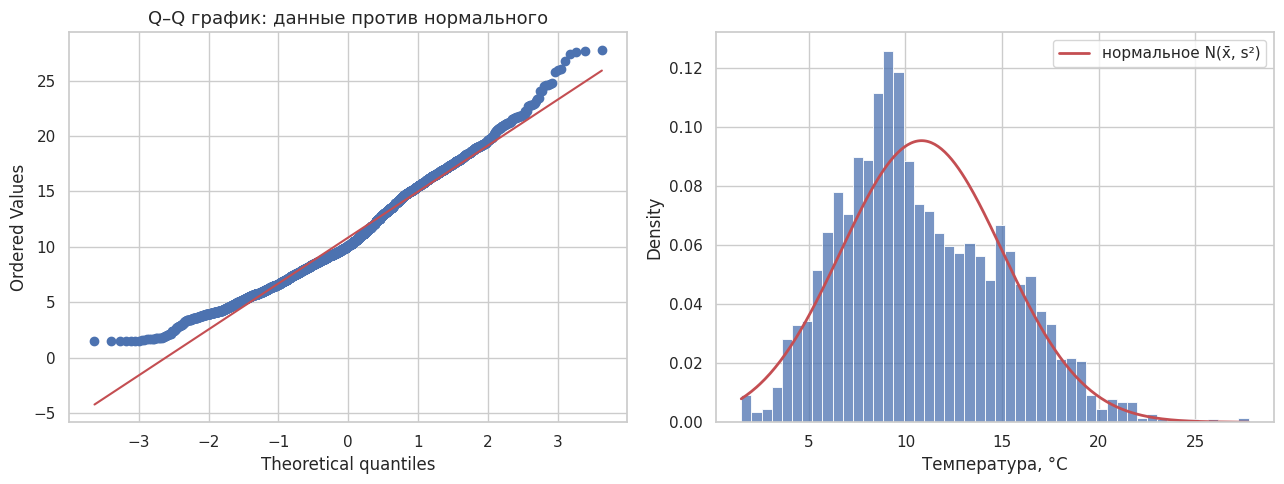

In [17]:
alpha = 0.05
test_sample = rng.choice(arr, size=5000, replace=False)

# 1) Шапиро-Уилк
sh_stat, sh_p = stats.shapiro(test_sample)
# 2) Д'Агостино-Пирсон (по асимметрии и эксцессу)
da_stat, da_p = stats.normaltest(test_sample)
# 3) Колмогоров-Смирнов с оценёнными параметрами (p-value приближённый, т.к. параметры оценены по этим же данным)
ks_stat, ks_p = stats.kstest(test_sample, "norm", args=(test_sample.mean(), test_sample.std(ddof=1)))

res = pd.DataFrame({"статистика": [sh_stat, da_stat, ks_stat], "p-value": [sh_p, da_p, ks_p]},
                   index=["Shapiro-Wilk", "D'Agostino-Pearson", "Kolmogorov-Smirnov"])
res["решение при α=0.05"] = np.where(res["p-value"] < alpha, "отвергаем H0", "не отвергаем H0")
display(res)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(test_sample, dist="norm", plot=ax[0])
ax[0].set_title("Q–Q график: данные против нормального")
sns.histplot(test_sample, bins=50, stat="density", ax=ax[1])
xx = np.linspace(test_sample.min(), test_sample.max(), 300)
ax[1].plot(xx, stats.norm.pdf(xx, test_sample.mean(), test_sample.std(ddof=1)), "r", lw=2, label="нормальное N(x̄, s²)")
ax[1].set_xlabel("Температура, °C"); ax[1].legend()
plt.tight_layout(); plt.show()

**Гипотеза 2 (о нормальности на срезе).**
Температура зависит от глубины, поэтому на фиксированной глубине распределение может быть проще. Проверяем $H_0$: температура на поверхности ($0$ м) нормальна.

Измерений на поверхности: 32344
Shapiro-Wilk:        W = 0.9683, p = 7.53e-32
D'Agostino-Pearson:  stat = 573.59, p = 2.79e-125
skew = 0.775, excess kurtosis = 1.413


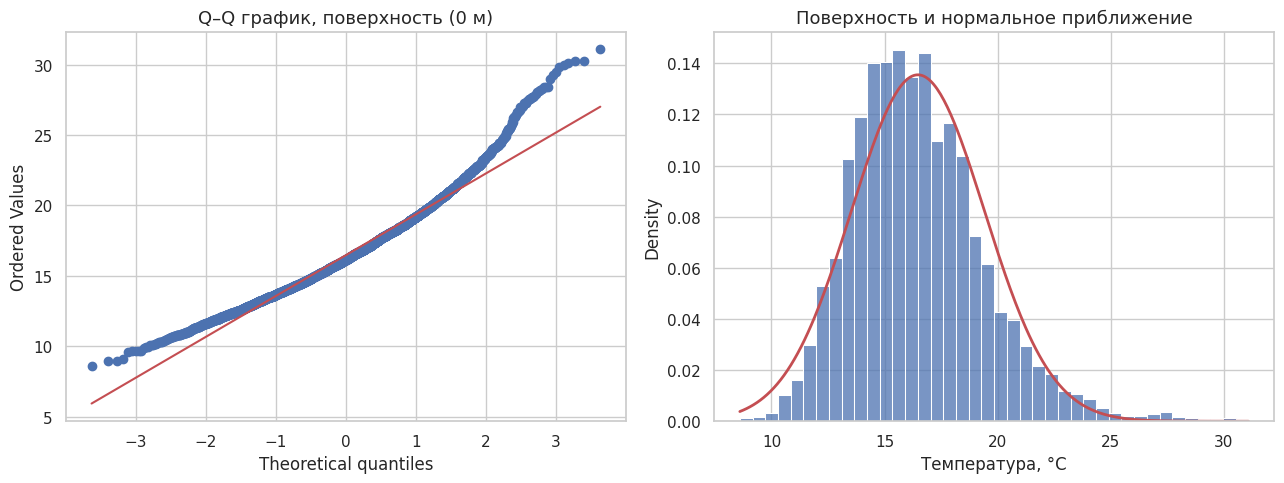

In [18]:
surf = surface.values
print(f"Измерений на поверхности: {len(surf)}")
surf_test = rng.choice(surf, size=min(5000, len(surf)), replace=False)

sh_stat, sh_p = stats.shapiro(surf_test)
da_stat, da_p = stats.normaltest(surf_test)
print(f"Shapiro-Wilk:        W = {sh_stat:.4f}, p = {sh_p:.3g}")
print(f"D'Agostino-Pearson:  stat = {da_stat:.2f}, p = {da_p:.3g}")
print(f"skew = {stats.skew(surf):.3f}, excess kurtosis = {stats.kurtosis(surf):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(surf_test, dist="norm", plot=ax[0]); ax[0].set_title("Q–Q график, поверхность (0 м)")
sns.histplot(surf_test, bins=40, stat="density", ax=ax[1])
xx = np.linspace(surf_test.min(), surf_test.max(), 300)
ax[1].plot(xx, stats.norm.pdf(xx, surf_test.mean(), surf_test.std(ddof=1)), "r", lw=2)
ax[1].set_xlabel("Температура, °C"); ax[1].set_title("Поверхность и нормальное приближение")
plt.tight_layout(); plt.show()

**Гипотеза 3 (о средних на разных глубинах).**
$H_0$: средняя температура на поверхности (0 м) и на глубине 500 м одинакова. $H_1$: различается. Используем t-критерий Уэлча (не требует равенства дисперсий) и непараметрический критерий Манна–Уитни (не требует нормальности).

In [19]:
deep = df.loc[df["Depthm"] == 500, "T_degC"].dropna().values
print(f"Измерений на 500 м: {len(deep)}; среднее = {deep.mean():.2f} °C; на поверхности: {surf.mean():.2f} °C")

t_stat, t_p = stats.ttest_ind(surf, deep, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(surf, deep, alternative="two-sided")
print(f"Welch t-test:  t = {t_stat:.2f}, p = {t_p:.3g}")
print(f"Mann-Whitney:  U = {u_stat:.0f}, p = {u_p:.3g}")

diff = surf.mean() - deep.mean()
se = np.sqrt(surf.var(ddof=1) / len(surf) + deep.var(ddof=1) / len(deep))
print(f"Разность средних = {diff:.2f} °C, 95% ДИ ≈ [{diff - 1.96*se:.2f}, {diff + 1.96*se:.2f}]")

Измерений на 500 м: 24663; среднее = 6.15 °C; на поверхности: 16.47 °C
Welch t-test:  t = 611.45, p = 0
Mann-Whitney:  U = 797634495, p = 0
Разность средних = 10.32 °C, 95% ДИ ≈ [10.28, 10.35]


**Вывод по гипотезам.**

**Гипотеза 1.** Для нормальности по всем глубинам (подвыборка 5000) три критерия дали p-value порядка $10^{-24}$–$10^{-38}$ (Shapiro–Wilk $W=0{,}980$, $p=3{,}5\cdot10^{-26}$; D'Agostino–Pearson $p=1{,}8\cdot10^{-38}$; Колмогоров–Смирнов $D=0{,}075$, $p=9{,}6\cdot10^{-25}$). Все $p<0{,}05$, поэтому $H_0$ **отвергаем**: температура всего океанского датасета не нормальная. Это согласуется с гистограммой, асимметрией 0,49 и сравнением AIC.

**Гипотеза 2.** Я ожидал, что на одной глубине (0 м) распределение будет ближе к нормальному, но гипотеза **не подтвердилась**: Shapiro–Wilk $W=0{,}968$, $p=7{,}5\cdot10^{-32}$, D'Agostino–Pearson $p=2{,}8\cdot10^{-125}$, асимметрия 0,78, эксцесс 1,41. Поверхностная температура тоже заметно скошена вправо и с тяжёлыми хвостами. Видимо, срез по глубине не убирает остальных источников разброса: на поверхности смешаны разные сезоны, годы и районы.

**Гипотеза 3.** Средняя температура на поверхности (16,47 °C, 32 344 измерения) и на глубине 500 м (6,15 °C, 24 663 измерения) различается: t-критерий Уэлча $t=611$, p меньше любого разумного порога (в расчёте вышел 0 из-за округления компьютера), разность средних 10,32 °C, 95 % ДИ [10,28; 10,35]. Критерий Манна–Уитни тоже даёт $p\approx0$, а $U/(n_1 n_2)=0{,}9999$: почти для любой пары «поверхность — 500 м» поверхность оказывается теплее. $H_0$ **отвергаем**. Оговорка: измерения с одной станции зависимы между собой, поэтому реальные p-value и ДИ менее надёжны, чем показывают формулы. Но разница в 10 °C настолько велика, что вывод от этого не меняется.

### Выводы (Random Variable 01 — температура воды)

1. **Случайность.** Температура воды — случайная величина. На одной глубине (0 м) из 32 344 измерений получилось 2 873 разных значения, от 8,36 до 31,14 °C. Модель «температура = функция(глубина)» объясняет только $R^2 = 0{,}782$ изменчивости, остальное определяется сезоном, местом, течениями, годом и погрешностью измерения, которые заранее не посчитать.

2. **EDA.** Среднее 10,80 °C, медиана 10,06 °C, std 4,24 °C, асимметрия +0,49, эксцесс −0,11. Правый хвост длиннее. По правилу 1,5×IQR найдено 3 738 выбросов (0,44 %), все сверху (23,2–31,1 °C). Я их оставил: это реальные тёплые воды, а не ошибки. Гистограмма имеет несколько «горбов», потому что в данных смешаны разные глубины и условия.

3. **Нормализация.** Min-max переводит данные в [0, 1], Z-преобразование даёт среднее 0 и std 1. Форма распределения (асимметрия 0,489) не меняется, меняются только сдвиг и масштаб. К стандартному нормальному приводить данные нельзя, потому что они не нормальные.

4. **Состоятельность.** Среднее и дисперсия выборки сходятся к истинным (10,80 °C и 18,01 °C²) при росте n, коридор разброса сужается, ошибка среднего убывает как $\sigma/\sqrt{n}$. При n около 10 оценки сильно «скачут», при n порядка тысяч уже близки к истинным.

5. **Выборки.** При n = 5000 из 853 900 обе схемы дают статистики, отличающиеся от генеральных примерно на 1 % и меньше. На малой совокупности (N = 2000, n = 1500) дисперсия среднего без возвращения меньше в 0,26 раза, что совпадает с теоретической поправкой $\frac{N-n}{N-1}\approx0{,}25$.

6. **Распределение.** Нормальное описывает температуру хуже всех (KS D = 0,071). Лучше всех по AIC скошенное нормальное ($\alpha=3{,}11$, $\xi=5{,}74$, $\omega=6{,}58$), по KS близко к нему гамма. Мелкие «горбы» эти распределения не передают, потому что реально данные — смесь нескольких компонент.

7. **Гипотезы.** Нормальность отвергнута и для всех данных ($p\sim10^{-26}$), и для поверхности ($p\sim10^{-32}$), то есть срез по глубине не сделал распределение нормальным. Гипотеза о равенстве средних на 0 и 500 м отвергнута (разность 10,32 °C). Для датасета это значит, что температура определяется прежде всего глубиной (холодная вода глубже), но на фиксированной глубине остаётся заметный разброс от сезона и места.

8. **Что можно улучшить.** Разбить данные по сезонам и годам, посмотреть влияние Эль-Ниньо, описать распределение смесью нормальных, добавить солёность как вторую величину и проверить независимость от температуры. Потом сравнить свои выводы с готовыми разборами датасета.